# Savitsky Sensitivity Analysis

In [59]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'hull/savitsky_sensitivity.py').exists())
if str(ROOT / 'hull') not in sys.path:
    sys.path.insert(0, str(ROOT / 'hull'))
from savitsky_sensitivity import load_baseline, study, export_study


## 1. Pick Baselines

`BASELINE_FILE` accepts the current input JSON. 

`BASELINE_OVERRIDES` changes the boat being studied. **Edit the lists at the top of the next cell** to choose your comparisons

`REQUIRE_UNIFORM_AFT = False` allows sensitivity estimates beyond the uniform aft section, with geometry flags retained. Set it to `True` to require both baseline and variant to fit that assumption.


In [60]:
# Baseline boat: change this path to load another saved input file.
BASELINE_FILE = ROOT / 'optimization/savitsky/current-hull-inputs.json'
BASELINE_OVERRIDES = {}  # Optional absolute SI values, e.g. {'mass_kg': 60.0, 'lcg_m': 0.62}

# EDIT THESE LISTS: each number creates a separate change from the baseline.
# Percent changes: -10 means 10% smaller/lighter; +10 means 10% larger/heavier.
# Example: add +20 to BEAM_CHANGES_PCT to also compare a 20% wider boat.
# Use [] to skip a parameter. The unchanged baseline is always included.
BEAM_CHANGES_PCT = [-10, -5, +5, +10, +20]
MASS_CHANGES_PCT = [-5, +5]
LENGTH_CHANGES_PCT = [-20,+20]             # e.g. [-5, +5]; changes hull-length checks, not resistance directly.

# Fixed offsets: inches for CG and thrust positions, degrees for angles.
LCG_OFFSETS_IN = [-10,-1, +1,+10]            # Negative = aft; positive = forward.
VCG_OFFSETS_IN = []                 # e.g. [-1, +1]; negative = lower; positive = higher.
THRUST_HEIGHT_OFFSETS_IN = []       # e.g. [-1, +1]; negative = lower; positive = higher.
THRUST_X_OFFSETS_IN = []            # e.g. [-1, +1]; negative = aft; positive = forward.
DEADRISE_OFFSETS_DEG = [-2, +2]      # Negative = flatter; positive = deeper V.
THRUST_ANGLE_OFFSETS_DEG = [-2, +2]  # Added to the baseline thrust angle.

# Load the baseline and convert the lists to the absolute values the model uses.
config, imported_speeds = load_baseline(BASELINE_FILE)
config['inputs'].update(BASELINE_OVERRIDES)
p = config['inputs']
SPEEDS_MPH = imported_speeds or list(range(0, 31, 2))
VARIATIONS = {
    'length_m': [p['length_m'] * (1 + pct / 100) for pct in LENGTH_CHANGES_PCT],
    'beam_m': [p['beam_m'] * (1 + pct / 100) for pct in BEAM_CHANGES_PCT],
    'mass_kg': [p['mass_kg'] * (1 + pct / 100) for pct in MASS_CHANGES_PCT],
    'lcg_m': [p['lcg_m'] + inches * 0.0254 for inches in LCG_OFFSETS_IN],
    'vcg_m': [p['vcg_m'] + inches * 0.0254 for inches in VCG_OFFSETS_IN],
    'thrust_height_m': [p['thrust_height_m'] + inches * 0.0254 for inches in THRUST_HEIGHT_OFFSETS_IN],
    'thrust_x_m': [p['thrust_x_m'] + inches * 0.0254 for inches in THRUST_X_OFFSETS_IN],
    'deadrise_deg': [p['deadrise_deg'] + deg for deg in DEADRISE_OFFSETS_DEG],
    'thrust_angle_deg': [p['thrust_angle_deg'] + deg for deg in THRUST_ANGLE_OFFSETS_DEG],
}
SCENARIOS = {}  # e.g. {'battery move': {'lcg_m': 0.62, 'vcg_m': 0.14}}
REQUIRE_UNIFORM_AFT = False


payload = study(config, SPEEDS_MPH, VARIATIONS, SCENARIOS, REQUIRE_UNIFORM_AFT)
curves = pd.DataFrame(payload['results'])
sensitivity = pd.DataFrame(payload['sensitivities'])
print('Equation fingerprint:', payload['engine_functions_sha256'])
print('Units: length m; mass kg; angles deg; speed mph; force N; effective power kW.')
display(pd.DataFrame([{'input': k, 'baseline': v,
                      'unit': config.get('input_notes', {}).get(k, {}).get('unit', 'see input schema')}
                     for k, v in p.items()]))
display(curves.groupby('scenario', sort=False).agg(
    points=('speed_mph', 'size'), solved=('solved', 'sum'),
    within_screen=('screen_ok', 'sum'), within_uniform_aft=('geometry_ok', 'sum')))
print('Sensitivity outside uniform aft section:', not REQUIRE_UNIFORM_AFT)


Equation fingerprint: beea4b9359303787728b3c9ba4a1cdbd7ed55d93c2c105ee1c87d572b792f567
Units: length m; mass kg; angles deg; speed mph; force N; effective power kW.


,input,baseline,unit
0,length_m,1.828800,m
1,beam_m,0.304800,m
2,mass_kg,56.811991,kg
3,deadrise_deg,13.161188,deg
4,lcg_m,0.598094,m
5,vcg_m,0.154407,m
6,thrust_height_m,-0.032824,m
7,thrust_x_m,-0.122527,m
8,thrust_angle_deg,15.000000,deg
9,density_kg_m3,998.200000,kg/m³


,points,solved,within_screen,within_uniform_aft
scenario,,,,
baseline,16,14,11,0
length_m=1.46304,16,14,11,0
length_m=2.19456,16,14,11,0
beam_m=0.27432,16,14,10,2
beam_m=0.28956,16,14,11,0
beam_m=0.32004,16,14,12,0
beam_m=0.33528,16,13,12,0
beam_m=0.36576,16,13,13,0
mass_kg=53.9713912126,16,14,11,0


Sensitivity outside uniform aft section: True


Select `PLOT_PARAMETER`. Options:
- 'beam_m'
- 'mass_kg'
- 'length_m'
- 'lcg_m'
- 'vcg_m'
- 'deadrise_deg' 
- 'thrust_height_m'
- 'thrust_x_m'

In [61]:
PLOT_PARAMETER = 'lcg_m'
DETAIL_MPH = 10
SHOW_OUTSIDE_LIMITS = True

## 2. Speed curves

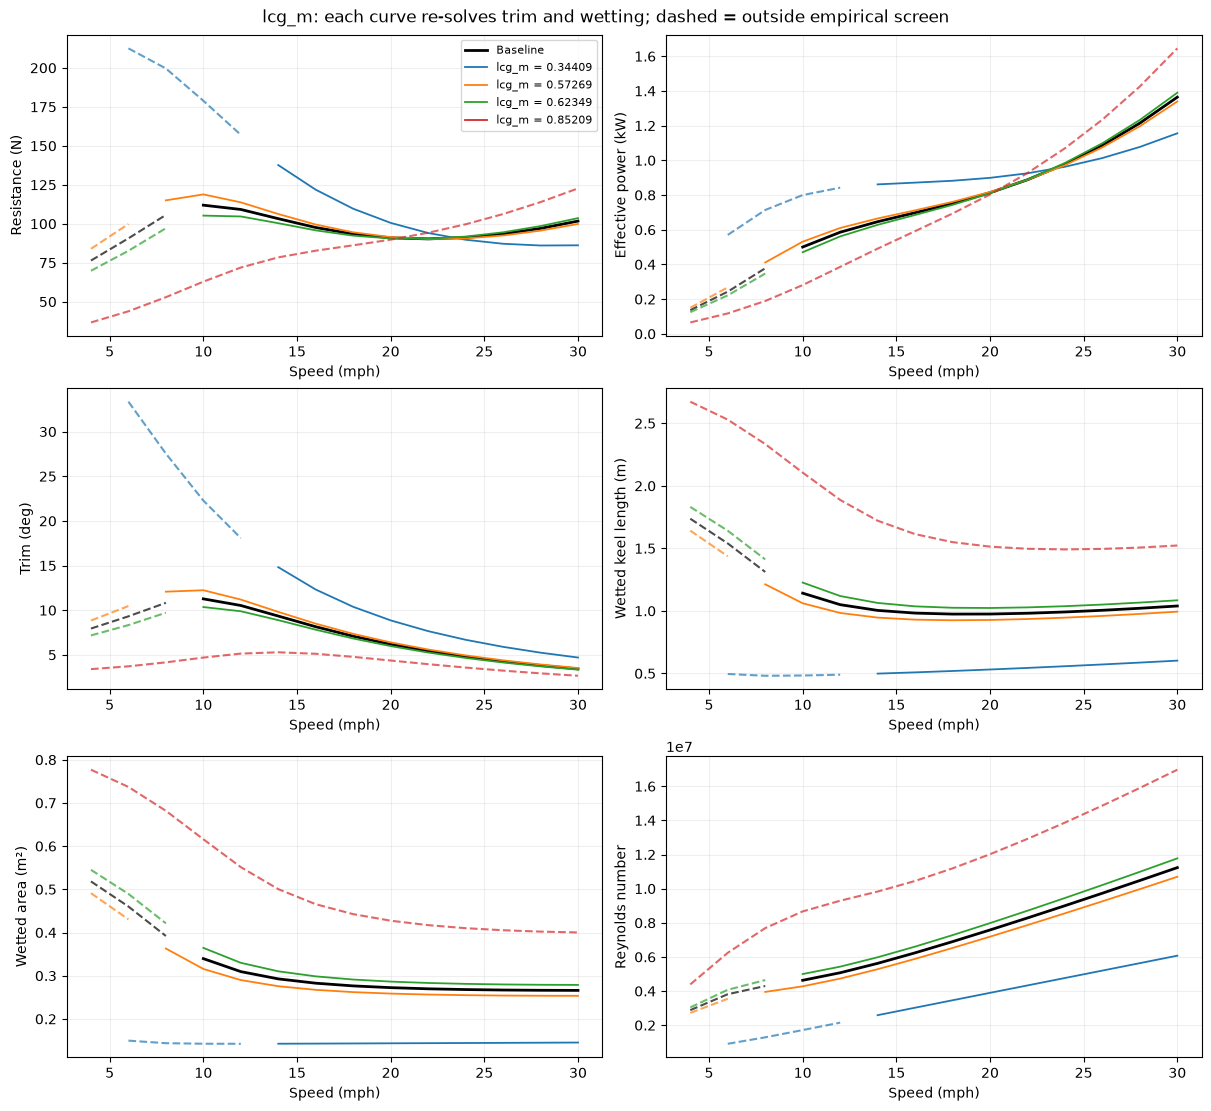

In [62]:
def label_for(name, frame):
    row = frame.iloc[0]
    if name == 'baseline':
        return 'Baseline'
    key = row['parameter']
    if pd.notna(key):
        return f"{key} = {row['parameter_value']:.5g}"
    return name.removeprefix('scenario:')

selected = curves[(curves['scenario'] == 'baseline') |
                  (curves['parameter'] == PLOT_PARAMETER) |
                  curves['scenario'].str.startswith('scenario:')]
metrics = [('resistance_n', 'Resistance (N)'), ('effective_power_kw', 'Effective power (kW)'),
           ('trim_deg', 'Trim (deg)'), ('keel_wetted_m', 'Wetted keel length (m)'),
           ('wetted_area_m2', 'Wetted area (m²)'), ('reynolds_number', 'Reynolds number')]
fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
for name, frame in selected.groupby('scenario', sort=False):
    frame = frame.sort_values('speed_mph')
    color = 'black' if name == 'baseline' else None
    for ax, (metric, ylabel) in zip(axes.flat, metrics):
        # Static power is deliberately not connected to the running model.
        y = frame.reindex(columns=[metric])[metric]
        line, = ax.plot(frame['speed_mph'], y.where(frame['screen_ok']),
                        label=label_for(name, frame), color=color, linewidth=2 if name == 'baseline' else 1.3)
        if SHOW_OUTSIDE_LIMITS:
            ax.plot(frame['speed_mph'], y.where(frame['solved'] & ~frame['screen_ok']),
                    '--', color=line.get_color(), alpha=0.7)
        ax.set(xlabel='Speed (mph)', ylabel=ylabel)
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'{PLOT_PARAMETER}: each curve re-solves trim and wetting; dashed = outside empirical screen')
plt.show()


## 3. Pressure v. Friction

This separates the two resistance contributions. A design can reduce pressure drag while increasing friction, so neither trim nor wetted area alone is the efficiency objective.

**Pressure Drag**: backward component of the pressure force supporting the boat. Dependecies:
- Lift 
- Trim

**Friction Drag**: resistance from water flowing along the wetted bottom. Dependencies:
- Wetted area
- Speed
- Friction Coefficient


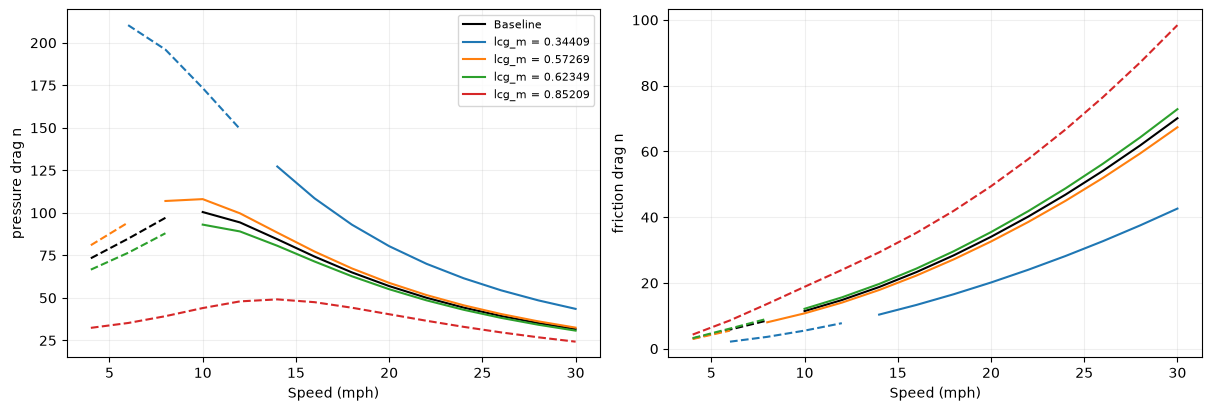

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, frame in selected.groupby('scenario', sort=False):
    frame = frame.sort_values('speed_mph')
    for ax, metric in zip(axes, ['pressure_drag_n', 'friction_drag_n']):
        y = frame.reindex(columns=[metric])[metric]
        line, = ax.plot(frame['speed_mph'], y.where(frame['screen_ok']),
                        label=label_for(name, frame), color='black' if name == 'baseline' else None)
        if SHOW_OUTSIDE_LIMITS:
            ax.plot(frame['speed_mph'], y.where(frame['solved'] & ~frame['screen_ok']),
                    '--', color=line.get_color())
        ax.set(xlabel='Speed (mph)', ylabel=metric.replace('_', ' '))
        ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
plt.show()


## 4. Sensitivity Changes over Speed Variable

**Percent change:** % difference from origninal

**Normalized sensitivity:** Compares the size change of the result to the size of our adjustment.


### **Plot Metrics**
- 'resistance_n'
- 'effective_power_kw'
- 'trim_deg'
- 'keel_wetted_m'
- 'wetted_area_m2'
- 'reynolds_number'
- 'pressure_drag_n'
- 'friction_drag_n'
- 'thrust_n'

In [64]:
PLOT_METRIC = 'trim_deg'

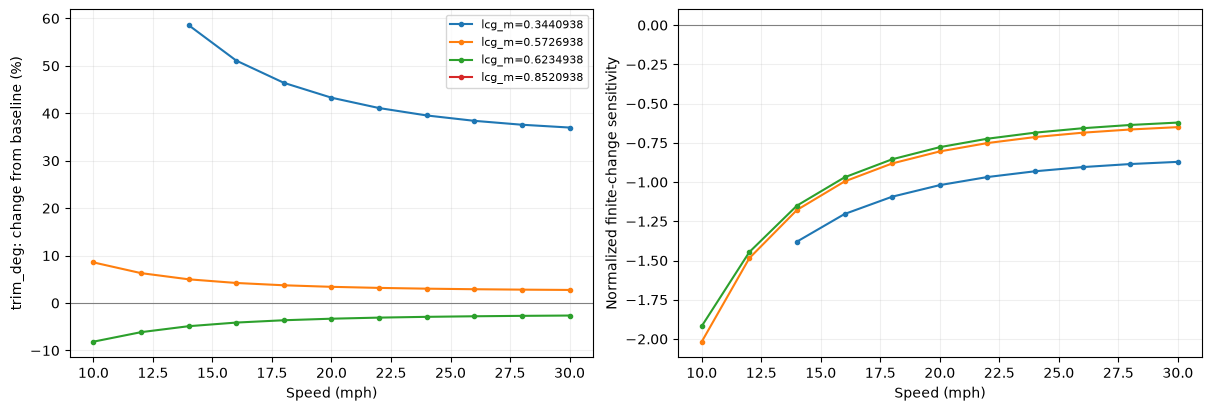

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
if not sensitivity.empty:
    subset = sensitivity[(sensitivity['parameter'] == PLOT_PARAMETER) &
                         (sensitivity['metric'] == PLOT_METRIC)]
    for name, frame in subset.groupby('scenario', sort=False):
        frame = frame.sort_values('speed_mph')
        for ax, field in zip(axes, ['percent_change', 'elasticity']):
            ax.plot(frame['speed_mph'], frame[field], marker='.', label=name)
    for ax in axes:
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.set_xlabel('Speed (mph)')
        ax.grid(alpha=0.2)
    axes[0].set_ylabel(f'{PLOT_METRIC}: change from baseline (%)')
    axes[1].set_ylabel('Normalized finite-change sensitivity')
    if not subset.empty:
        axes[0].legend(fontsize=8)
else:
    axes[0].text(0.5, 0.5, 'Add one-input variations to compute sensitivities', ha='center')
plt.show()


## 5. Inspect exact numbers and flags

Choose `DETAIL_MPH` on the actual speed grid. The raw rows include every intermediate result, all input values (`input__...` columns), model status, warnings and geometry flags. Filter this table or the exported CSV to inspect Reynolds number, friction coefficient or force/moment balances.


In [66]:
detail = curves[curves['speed_mph'] == DETAIL_MPH]
if detail.empty:
    print('Choose DETAIL_MPH from:', SPEEDS_MPH)
else:
    display(detail.reindex(columns=['scenario', 'speed_mph', 'trim_deg', 'keel_wetted_m',
        'resistance_n', 'effective_power_kw', 'pressure_drag_n', 'friction_drag_n',
        'reynolds_number', 'status', 'geometry_ok', 'geometry_warning', 'warnings']).round(6))
if not sensitivity.empty:
    display(sensitivity[(sensitivity['speed_mph'] == DETAIL_MPH) &
                        (sensitivity['metric'] == PLOT_METRIC)].round(6))


,scenario,speed_mph,trim_deg,keel_wetted_m,resistance_n,effective_power_kw,pressure_drag_n,friction_drag_n,reynolds_number,status,geometry_ok,geometry_warning,warnings
5,baseline,10,11.272090,1.141791,111.930644,0.500375,100.486093,11.444551,4.631622e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
21,length_m=1.46304,10,11.272090,1.141791,111.930644,0.500375,100.486093,11.444551,4.631622e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
37,length_m=2.19456,10,11.272090,1.141791,111.930644,0.500375,100.486093,11.444551,4.631622e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
53,beam_m=0.27432,10,11.745714,1.169498,114.820204,0.513292,104.265455,10.554748,4.786370e+06,outside_limits,False,Wetting beyond assumed uniform aft section.,[Mean wetted length / beam exceeds 4.]
69,beam_m=0.28956,10,11.511601,1.154669,113.402591,0.506955,102.402585,11.000007,4.704901e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
85,beam_m=0.32004,10,11.029496,1.130683,110.422668,0.493633,98.533760,11.888907,4.565639e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
101,beam_m=0.33528,10,10.785871,1.121177,108.895131,0.486805,96.561701,12.333430,4.506134e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
117,beam_m=0.36576,10,10.302221,1.106380,105.836483,0.473131,92.612690,13.223793,4.403675e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
133,mass_kg=53.9713912126,10,10.824545,1.144509,103.501612,0.462694,92.041449,11.460163,4.642628e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]
149,mass_kg=59.6525902876,10,11.711729,1.139337,120.608938,0.539170,109.180028,11.428910,4.620863e+06,within_screen,False,Wetting beyond assumed uniform aft section.,[]


,scenario,speed_mph,parameter,parameter_value,parameter_baseline,metric,eligible,reason,change,slope,percent_change,elasticity,variant_status,baseline_status,variant_geometry_ok,baseline_geometry_ok
47,length_m=1.46304,10,length_m,1.463040,1.828800,trim_deg,True,ok,0.000000,-0.000000,0.000000,-0.000000,within_screen,within_screen,False,False
191,length_m=2.19456,10,length_m,2.194560,1.828800,trim_deg,True,ok,0.000000,0.000000,0.000000,0.000000,within_screen,within_screen,False,False
335,beam_m=0.27432,10,beam_m,0.274320,0.304800,trim_deg,False,Not both within empirical screen / required ge...,NaN,NaN,NaN,NaN,outside_limits,within_screen,False,False
479,beam_m=0.28956,10,beam_m,0.289560,0.304800,trim_deg,True,ok,0.239511,-15.715976,2.124819,-0.424964,within_screen,within_screen,False,False
623,beam_m=0.32004,10,beam_m,0.320040,0.304800,trim_deg,True,ok,-0.242593,-15.918207,-2.152161,-0.430432,within_screen,within_screen,False,False
767,beam_m=0.33528,10,beam_m,0.335280,0.304800,trim_deg,True,ok,-0.486219,-15.952056,-4.313474,-0.431347,within_screen,within_screen,False,False
911,beam_m=0.36576,10,beam_m,0.365760,0.304800,trim_deg,True,ok,-0.969869,-15.909930,-8.604166,-0.430208,within_screen,within_screen,False,False
1055,mass_kg=53.9713912126,10,mass_kg,53.971391,56.811991,trim_deg,True,ok,-0.447545,0.157553,-3.970384,0.794077,within_screen,within_screen,False,False
1199,mass_kg=59.6525902876,10,mass_kg,59.652590,56.811991,trim_deg,True,ok,0.439640,0.154770,3.900249,0.780050,within_screen,within_screen,False,False
1343,lcg_m=0.3440938,10,lcg_m,0.344094,0.598094,trim_deg,False,Not both within empirical screen / required ge...,NaN,NaN,NaN,NaN,outside_limits,within_screen,True,False


## 6. Export or restart an analysis

Set `EXPORT_NAME` to a new folder name, then run this cell. It writes three readable files under `outputs/savitsky/sensitivity/`:

- `study.json`: complete baseline configuration, assumptions, variations, speed grid, model equation fingerprint, all curves and sensitivity rows. Use this file as a future `BASELINE_FILE`.
- `curves.csv`: one scenario/speed per row, every input and computed intermediate, plus status and warnings. Unavailable values are empty cells.
- `sensitivities.csv`: parameter/output/speed comparisons, percent changes, physical slopes and normalized sensitivity, with eligibility reasons.

Exports refuse existing names. JSON restores inputs and a speed grid; edit `VARIATIONS` to define the next study. Previously saved curves remain available in the JSON for independent analysis. No files are written while `EXPORT_NAME = None`.


In [67]:
EXPORT_NAME = None  # e.g. 'beam-mass-study-01'
if EXPORT_NAME is not None:
    if not isinstance(EXPORT_NAME, str) or not EXPORT_NAME or Path(EXPORT_NAME).name != EXPORT_NAME or EXPORT_NAME in {'.', '..'}:
        raise ValueError('Use a new folder name without directory components.')
    folder = export_study(payload, ROOT / 'outputs/savitsky/sensitivity' / EXPORT_NAME)
    print('Saved:', folder)
else:
    print('Export disabled; set EXPORT_NAME to save CSV and JSON.')


Export disabled; set EXPORT_NAME to save CSV and JSON.
